# Résultats scolaires : où faut-il progresser ?

**Problème :** Comparer les notes par matière et classe. Anomalies : note manquante, note hors de 0–20, texte mal formaté.

Les données sont synthétiques. Exécute les cellules dans l'ordre. Le fichier `donnees.xlsx` doit rester dans le même dossier que ce notebook.

## Étape 1 :Lire et explorer les données

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
df = pd.read_excel("donnees.xlsx", sheet_name="donnees")
print("Dimensions :", df.shape)
display(df.head())
display(df.sample(min(5, len(df)), random_state=1))


Dimensions : (28, 5)


,etudiant_id,classe,matiere,note,absences
0,E001,3IIR-A,Réseaux,11.1,3
1,E002,4IIR-B,Réseaux,13.2,0
2,E003,3IIR-A,Réseaux,NaN,8
3,E004,4IIR-A,Maths,14.1,4
4,E005,3IIR-A,SQL,9.3,3


,etudiant_id,classe,matiere,note,absences
24,E025,4IIR-A,Réseaux,13.6,2
17,E018,3IIR-A,SQL,9.8,2
19,E020,4IIR-A,Python,7.1,1
20,E021,4IIR-B,SQL,12.9,4
14,E015,4IIR-A,python,19.1,6


## Étape 2 :Comprendre la structure

In [5]:
import os

print("Dossier actuel :", os.getcwd())
print("Fichiers disponibles :", os.listdir())

Dossier actuel : d:\analyse des  donnees\mini-projets-data\resultats-etudiants
Fichiers disponibles : ['analyse.ipynb', 'donnees.xlsx']


In [6]:
df.info()
display(df.describe(include="all").T)
print("Colonnes :", df.columns.tolist())


<class 'pandas.DataFrame'>
RangeIndex: 28 entries, 0 to 27
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   etudiant_id  28 non-null     str    
 1   classe       28 non-null     str    
 2   matiere      28 non-null     str    
 3   note         27 non-null     float64
 4   absences     28 non-null     int64  
dtypes: float64(1), int64(1), str(3)
memory usage: 1.2 KB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
etudiant_id,28,28,E001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
classe,28,3,3IIR-A,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN
matiere,28,5,Python,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
note,27.0,NaN,NaN,NaN,12.733333,3.822605,7.1,10.15,12.9,14.3,25.0
absences,28.0,NaN,NaN,NaN,4.25,2.473938,0.0,2.0,4.0,6.25,8.0


Colonnes : ['etudiant_id', 'classe', 'matiere', 'note', 'absences']


## Étape 3 :Détecter les anomalies

In [7]:
print("Valeurs manquantes :")
display(df.isna().sum())
print("Lignes dupliquées :", df.duplicated().sum())
for col in df.select_dtypes(include=["object", "string"]).columns:
    print(f"\\n{col} :", df[col].dropna().astype(str).unique()[:15])


Valeurs manquantes :


etudiant_id    0
classe         0
matiere        0
note           1
absences       0
dtype: int64

Lignes dupliquées : 0
\netudiant_id : <StringArray>
['E001', 'E002', 'E003', 'E004', 'E005', 'E006', 'E007', 'E008', 'E009',
 'E010', 'E011', 'E012', 'E013', 'E014', 'E015']
Length: 15, dtype: str
\nclasse : <StringArray>
['3IIR-A', '4IIR-B', '4IIR-A']
Length: 3, dtype: str
\nmatiere : <StringArray>
['Réseaux', 'Maths', 'SQL', 'Python', ' python ']
Length: 5, dtype: str


## Étape 4 :Nettoyer les données

On conserve `df` intact et on travaille sur une copie `df_clean`. Adapte les règles selon le problème métier.

In [8]:
df_clean = df.copy()
df_clean = df_clean.drop_duplicates()

# Nettoyage simple des espaces dans les colonnes texte
for col in df_clean.select_dtypes(include=["object", "string"]).columns:
    df_clean[col] = df_clean[col].astype("string").str.strip()

df_clean["matiere"] = df_clean["matiere"].str.strip().str.title()

print("Dimensions après nettoyage :", df_clean.shape)
display(df_clean.head())

Dimensions après nettoyage : (28, 5)


,etudiant_id,classe,matiere,note,absences
0,E001,3IIR-A,Réseaux,11.1,3
1,E002,4IIR-B,Réseaux,13.2,0
2,E003,3IIR-A,Réseaux,NaN,8
3,E004,4IIR-A,Maths,14.1,4
4,E005,3IIR-A,Sql,9.3,3


## Étape 5 :Analyse avec Pandas et calculs NumPy

In [9]:
df_clean["note"] = pd.to_numeric(df_clean["note"], errors="coerce")
df_analyse = df_clean[df_clean["note"].between(0,20)].copy()
display(df_analyse.groupby("matiere")["note"].agg(["mean","median","min","max","count"]).round(2))
print("Moyenne des notes valides :", np.mean(df_analyse["note"]))


,mean,median,min,max,count
matiere,,,,,
Maths,14.46,14.5,11.9,17.2,5
Python,12.02,11.7,7.1,19.1,8
Réseaux,11.57,11.5,9.2,13.6,6
Sql,11.56,12.9,7.6,15.0,7


Moyenne des notes valides : 12.261538461538462


## Étape 6 :Visualisation avec Matplotlib

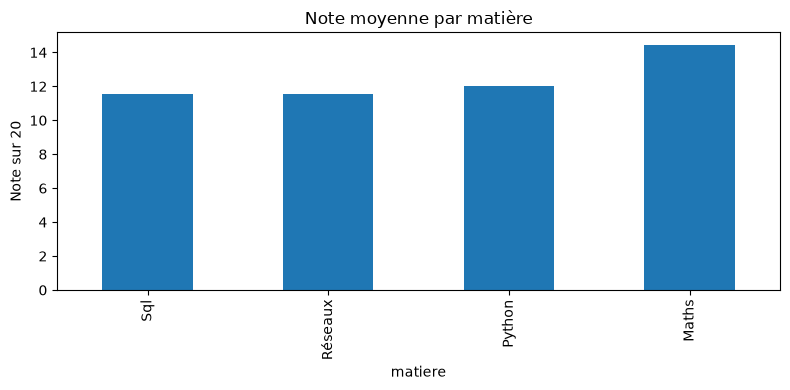

In [10]:
df_analyse.groupby("matiere")["note"].mean().sort_values().plot(kind="bar", figsize=(8,4))
plt.title("Note moyenne par matière")
plt.ylabel("Note sur 20")
plt.tight_layout()
plt.show()


## Exporter le résultat nettoyé

In [11]:
df_clean.to_csv("donnees_nettoyees.csv", index=False, encoding="utf-8-sig")
df_clean.to_excel("donnees_nettoyees.xlsx", index=False)
print("Export terminé.")


Export terminé.
